# 02. 외부 데이터 EDA: AI Hub 경구약제 조합 이미지

[AI Hub 경구약제 이미지 데이터](https://www.aihub.or.kr/aihubdata/data/view.do?currMenu=115&topMenu=100&aihubDataSe=data&dataSetSn=576)(dataSetSn=576) 중
**조합 데이터만**, 그중 **`TL_2`와 그 원천 `TS_2`를 뺀** zip을 봅니다.
검증용(`VS_1`·`VL_1`)은 `VS_1`이 팀 Drive에 올라오기 전까지 `EXCLUDE`로 뺍니다. 대회 데이터 EDA는 `01_eda.ipynb`에 있습니다.

zip은 팀 Google Drive 공유 폴더(`aihub_pill`)에 있습니다. 노트북이 그 폴더를 받아서 풀고 읽으므로
**Colab에서는 위에서부터 실행만 하면 됩니다.** GPU는 필요 없습니다. 이미 받은 zip과 이미 푼 zip은 건너뜁니다.

| | zip 받는 곳 | 푸는 곳 |
|---|---|---|
| Colab | `data/external/aihub_zips` (런타임 디스크) | `data/external/aihub_combo` |
| 로컬 | 같음. `.env`에 `AIHUB_ZIP_DIR`이 있으면 받지 않고 그 폴더(예: Drive 데스크톱)를 씀 | 같음. `.env`의 `AIHUB_EXTRACT_DIR`로 바꿀 수 있음 |

- 폴더 링크는 `AIHUB_URL`로 받습니다. 저장소가 public이라 노트북에 적지 않습니다.
  환경 변수(`.env`, Colab은 Upload to Colab으로 올린 `/content/.env`) → Colab 보안 비밀 → 입력창 순서로 찾습니다.
- 폴더는 "링크가 있는 모든 사용자"로 공유되어 있어야 받을 수 있습니다.
- 용량: zip 약 24GB + 푼 파일 약 24GB. Colab 기본 디스크로 충분합니다.
- AI Hub는 해외 IP 다운로드를 막아 Colab에서 AI Hub로부터 직접 받을 수 없습니다. Drive 폴더는 국내 PC에서 채웠습니다.
- 포함·제외 기준: 경로에 `조합`이 들어간 zip 중 이름 앞 구분자(`TL_2_조합.zip` → `TL_2`)가 `EXCLUDE`에 없는 것.
  `TS_*`·`VS_*`는 원천(이미지), `TL_*`·`VL_*`는 라벨(JSON)입니다.

In [7]:
import importlib.util
import os
import subprocess
import sys
from getpass import getpass
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None

BRANCH = "main"  # Colab에서 받을 저장소 브랜치
# 뺄 zip 구분자. TL_2 라벨을 안 쓰므로 그 이미지(TS_2)도 뺀다.
# 검증용(VL_1·VS_1)은 VS_1이 Drive에 올라오면 지워서 함께 본다.
EXCLUDE = ["TL_2", "TS_2", "VL_1", "VS_1"]
OVERWRITE = False  # True면 이미 푼 zip도 지우고 다시 푼다
SEED = 42

## 0. 환경 준비

Colab이면 저장소를 받아 import 경로에 넣고, 로컬이면 프로젝트 루트를 찾아 넣습니다. 그다음 `.env`를 읽습니다.
Colab에서는 `src.config`(torch·ultralytics·wandb)를 쓰지 않으므로 패키지를 따로 설치하지 않습니다.

In [8]:
if IN_COLAB:
    ROOT = Path("/content/pill-bbox")
    git = ["git", "-C", str(ROOT)]
    if ROOT.exists():
        subprocess.run([*git, "fetch", "-q", "origin", BRANCH], check=True)
        subprocess.run([*git, "checkout", "-q", BRANCH], check=True)
        subprocess.run([*git, "pull", "-q"], check=True)
    else:
        url = "https://github.com/def-uk/pill-bbox.git"
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, url, str(ROOT)], check=True)
    env_file = Path("/content/.env")  # VS Code에서 Upload to Colab으로 올린 .env
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
    env_file = ROOT / ".env"

os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
try:
    from dotenv import load_dotenv

    load_dotenv(env_file)  # 이미 설정된 환경 변수가 우선한다
except ImportError:
    pass

# 로컬은 AIHUB_ZIP_DIR(이미 있는 zip 폴더)·AIHUB_EXTRACT_DIR로 바꿀 수 있다.
# Colab은 올린 .env에 로컬 경로가 있어도 쓰지 않고 런타임 디스크에 받는다.
LOCAL_ZIP_DIR = None if IN_COLAB else os.getenv("AIHUB_ZIP_DIR")
ZIP_DIR = Path(LOCAL_ZIP_DIR or ROOT / "data" / "external" / "aihub_zips").expanduser()
extract_env = None if IN_COLAB else os.getenv("AIHUB_EXTRACT_DIR")
EXTRACT_DIR = Path(extract_env or ROOT / "data" / "external" / "aihub_combo").expanduser()
print(f"Colab: {IN_COLAB}\nzip 폴더: {ZIP_DIR}\n푸는 폴더: {EXTRACT_DIR}")

Colab: False
zip 폴더: /mnt/g/내 드라이브/pill-bbox/aihub_pill
푸는 폴더: /home/username/projects/pill-bbox/data/external/aihub_combo


In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from data_process.aihub_data import (
    download_drive_folder,
    extract_zips,
    find_combo_zips,
    list_combo_images,
    load_combo_annotations,
    zip_key,
)
from data_process.data_processing import build_cat_df, build_img_df, list_images, load_annotations
from visualization import draw_bboxes, image_grid, set_korean_font, show_image

np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
print("한글 폰트:", set_korean_font())

한글 폰트: Malgun Gothic


## 1. zip 받기와 압축 풀기

팀 Drive 폴더에서 zip을 받고(Colab에서 수 분) 풉니다(수십 분). 이미 받은 zip은 건너뛰고, 끊긴 파일은 이어 받습니다.
다 푼 zip에는 표시 파일이 남아 다음 실행에서 건너뜁니다. Colab 런타임이 새로 뜨면 런타임 디스크가 비므로 다시 받고 풉니다.

In [10]:
def env_value(name: str) -> str:
    """환경 변수 → Colab 보안 비밀 → 입력창 순서로 값을 찾는다."""
    if os.getenv(name):
        return os.environ[name]
    if IN_COLAB:
        from google.colab import userdata

        try:
            return userdata.get(name)
        except Exception:  # 보안 비밀이 없거나 이 노트북의 접근을 허용하지 않음
            pass
    return getpass(f"{name}: ")


if LOCAL_ZIP_DIR:
    print(f"받지 않고 AIHUB_ZIP_DIR을 씁니다: {ZIP_DIR}")
else:
    download_drive_folder(env_value("AIHUB_URL"), ZIP_DIR)

받지 않고 AIHUB_ZIP_DIR을 씁니다: /mnt/g/내 드라이브/pill-bbox/aihub_pill


In [11]:
zip_paths = find_combo_zips(ZIP_DIR, exclude=EXCLUDE)
zip_df = pd.DataFrame(
    {
        "zip": [p.name for p in zip_paths],
        "구분자": [zip_key(p) for p in zip_paths],
        "크기(GB)": [round(p.stat().st_size / 1e9, 2) for p in zip_paths],
    }
)
print(f"사용할 조합 zip: {len(zip_df)}개, 합계 {zip_df['크기(GB)'].sum():.1f}GB (제외: {EXCLUDE})")
display(zip_df)
if zip_df.empty:
    raise FileNotFoundError(f"{ZIP_DIR} 아래에 경로에 '조합'이 들어간 zip이 없습니다.")

사용할 조합 zip: 14개, 합계 25.6GB (제외: ['TL_2', 'TS_2', 'VL_1', 'VS_1'])


,zip,구분자,크기(GB)
0,TL_1_조합.zip,TL_1,0.01
1,TL_3_조합.zip,TL_3,0.01
2,TL_4_조합.zip,TL_4,0.01
3,TL_5_조합.zip,TL_5,0.01
4,TL_6_조합.zip,TL_6,0.01
5,TL_7_조합.zip,TL_7,0.01
6,TL_8_조합.zip,TL_8,0.01
7,TS_1_조합.zip,TS_1,3.71
8,TS_3_조합.zip,TS_3,3.65
9,TS_4_조합.zip,TS_4,3.57


In [12]:
extracted_dirs = extract_zips(zip_paths, EXTRACT_DIR, overwrite=OVERWRITE)

건너뜀(이미 풂): TL_1_조합
건너뜀(이미 풂): TL_3_조합
건너뜀(이미 풂): TL_4_조합
건너뜀(이미 풂): TL_5_조합
건너뜀(이미 풂): TL_6_조합
건너뜀(이미 풂): TL_7_조합
건너뜀(이미 풂): TL_8_조합
건너뜀(이미 풂): TS_1_조합
건너뜀(이미 풂): TS_3_조합
건너뜀(이미 풂): TS_4_조합
건너뜀(이미 풂): TS_5_조합
풀기 완료: TS_6_조합 (2000개 파일)
풀기 완료: TS_7_조합 (2000개 파일)
풀기 완료: TS_8_조합 (2000개 파일)


## 2. 데이터 로드

대회 데이터와 같은 로더(`data_process/data_processing.py`)를 씁니다. 표 구성도 `01_eda.ipynb`와 같습니다.

| 표 | 한 행 | 설명 |
|---|---|---|
| `ann_df` | bbox 1개 | 이미지 정보 + 약 정보 + bbox(COCO `[x, y, w, h]`). `zip_name`은 읽어 온 zip |
| `image_index` | 디스크의 이미지 1장 | `file_name`, `zip_name`, `path` |
| `img_df` | 이미지 1장 | 라벨 없는 이미지도 포함(`n_boxes=0`). `combo`는 파일 이름의 알약 조합 |
| `cat_df` | 클래스 1개 | `category_id` ↔ 약 이름, bbox 수, 이미지 수 |
| `load_error_df` | 오류 1건 | JSON 읽기·연결 실패 |

라벨 없는 이미지(`n_boxes=0`)가 있으면 원천·라벨 zip 짝이 맞는지(`EXCLUDE`) 확인합니다.

AI Hub 원본의 `category_id`는 모두 1(`Drug`)입니다. 로더가 대회 데이터처럼 `drug_N`의 숫자
(K-001900 → 1900)로 바꾸고 `category_name`은 `dl_name`으로 둡니다. 원래 값은 `category_id_raw`에 있습니다.
`dl_idx`는 약 코드보다 1 작은 값이라 클래스로 쓰지 않습니다.

In [13]:
ann_df, load_error_df = load_combo_annotations(extracted_dirs)
image_index = list_combo_images(extracted_dirs)
if image_index.empty:
    raise FileNotFoundError(
        "이미지가 없습니다. 원천 zip(TS·VS)이 팀 Drive에 있는지, EXCLUDE에 빠졌는지 확인하세요."
    )
img_df = build_img_df(ann_df, list(image_index["path"])).merge(
    image_index[["file_name", "zip_name"]].drop_duplicates("file_name"), on="file_name"
)
cat_df = build_cat_df(ann_df)
img_path = dict(zip(image_index["file_name"], image_index["path"], strict=True))

n_dup = image_index["file_name"].duplicated().sum()
print(f"bbox: {len(ann_df)}개, JSON: {ann_df['source_json'].nunique()}개, 클래스: {len(cat_df)}개")
print(f"이미지: {len(img_df)}장 (라벨 없음: {(img_df['n_boxes'] == 0).sum()}장)")
print(f"이름이 겹치는 이미지 파일: {n_dup}개")
print(f"JSON이 가리키지만 디스크에 없는 이미지: {len(set(ann_df['file_name']) - set(img_path))}장")
print(f"로드 오류: {len(load_error_df)}건")
if not load_error_df.empty:
    display(load_error_df.head(20))
display(ann_df.head(3))

bbox: 40413개, JSON: 40413개, 클래스: 116개
이미지: 14012장 (라벨 없음: 3515장)
이름이 겹치는 이미지 파일: 0개
JSON이 가리키지만 디스크에 없는 이미지: 6장
로드 오류: 1건


,source_json,annotation_id,stage,message,excluded
0,TL_6_조합/K-012247-016551-033009-044199_json/K-0...,None,parse,JSONDecodeError('Expecting value: line 59 colu...,True


,file_name,width,height,imgfile,drug_N,drug_S,back_color,drug_dir,light_color,camera_la,camera_lo,size,dl_idx,dl_mapping_code,dl_name,dl_name_en,img_key,dl_material,dl_material_en,dl_custom_shape,dl_company,dl_company_en,di_company_mf,di_company_mf_en,item_seq,di_item_permit_date,di_class_no,di_etc_otc_code,di_edi_code,chart,...,print_front,print_back,color_class1,color_class2,line_front,line_back,img_regist_ts,form_code_name,mark_code_front_anal,mark_code_back_anal,mark_code_front_img,mark_code_back_img,mark_code_front,mark_code_back,change_date,image_id,source_json,annotation_id,category_id,category_name,x,y,w,h,area,iscrowd,ignore,has_segmentation,zip_name,category_id_raw
0,K-000250-000573-002483-006192_0_2_0_2_70_000_2...,976,1280,K-000250-000573-002483-006192_0_2_0_2_70_000_2...,K-000250,정상알약,연회색 배경,앞면,주백색,70,0,200,249,K-000250,마그밀정(수산화마그네슘),Magmil Tab. 500mg,http://connectdi.com/design/img/drug/1NgBQQRiu...,수산화마그네슘,Magnesium Hydroxide,"정제, 저작정",삼남제약(주),Samnam,,,197400246,19740902,[02340]제산제,일반의약품,"653700240,A11800371",흰색의 원형정제,...,마크,마크,하양,,,,20041222,나정,"M,W,ⓦ","M,W,ⓦ",http://connectdi.com/design/img/drug/147938647...,http://connectdi.com/design/img/drug/147938647...,,,20150925,1,TL_1_조합/K-000250-000573-002483-006192_json/K-0...,1,250,마그밀정(수산화마그네슘),553.0,184.0,272.0,279.0,75888.0,0.0,0,False,TL_1_조합,1
1,K-000250-000573-002483-006192_0_2_0_2_75_000_2...,976,1280,K-000250-000573-002483-006192_0_2_0_2_75_000_2...,K-000250,정상알약,연회색 배경,앞면,주백색,75,0,200,249,K-000250,마그밀정(수산화마그네슘),Magmil Tab. 500mg,http://connectdi.com/design/img/drug/1NgBQQRiu...,수산화마그네슘,Magnesium Hydroxide,"정제, 저작정",삼남제약(주),Samnam,,,197400246,19740902,[02340]제산제,일반의약품,"653700240,A11800371",흰색의 원형정제,...,마크,마크,하양,,,,20041222,나정,"M,W,ⓦ","M,W,ⓦ",http://connectdi.com/design/img/drug/147938647...,http://connectdi.com/design/img/drug/147938647...,,,20150925,1,TL_1_조합/K-000250-000573-002483-006192_json/K-0...,1,250,마그밀정(수산화마그네슘),100.0,815.0,289.0,296.0,85544.0,0.0,0,False,TL_1_조합,1
2,K-000250-000573-002483-006192_0_2_0_2_90_000_2...,976,1280,K-000250-000573-002483-006192_0_2_0_2_90_000_2...,K-000250,정상알약,연회색 배경,앞면,주백색,90,0,200,249,K-000250,마그밀정(수산화마그네슘),Magmil Tab. 500mg,http://connectdi.com/design/img/drug/1NgBQQRiu...,수산화마그네슘,Magnesium Hydroxide,"정제, 저작정",삼남제약(주),Samnam,,,197400246,19740902,[02340]제산제,일반의약품,"653700240,A11800371",흰색의 원형정제,...,마크,마크,하양,,,,20041222,나정,"M,W,ⓦ","M,W,ⓦ",http://connectdi.com/design/img/drug/147938647...,http://connectdi.com/design/img/drug/147938647...,,,20150925,1,TL_1_조합/K-000250-000573-002483-006192_json/K-0...,1,250,마그밀정(수산화마그네슘),100.0,802.0,281.0,283.0,79523.0,0.0,0,False,TL_1_조합,1


## 3. 이미지당 bbox 개수 분포


전체 이미지: 14,012장


,이미지 수,비율(%)
이미지당 bbox 개수,,
0,"3,515",25.1%
2,1,0.0%
3,"1,619",11.6%
4,"8,860",63.2%
5,12,0.1%
6,5,0.0%


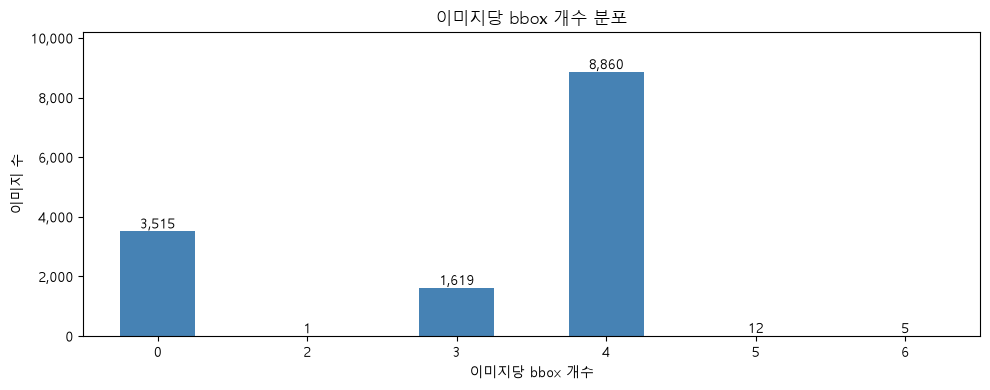

In [14]:
# bbox 개수별 이미지 수와 전체 이미지 대비 비율을 확인한다.
bbox_counts = img_df["n_boxes"].value_counts().sort_index().rename("이미지 수").to_frame()
bbox_counts.index.name = "이미지당 bbox 개수"
bbox_counts["비율(%)"] = bbox_counts["이미지 수"] / len(img_df) * 100
print(f"전체 이미지: {len(img_df):,}장")
display(bbox_counts.style.format({"이미지 수": "{:,.0f}", "비율(%)": "{:.1f}%"}))

ax = bbox_counts["이미지 수"].plot.bar(figsize=(10, 4), rot=0, color="steelblue")
ax.set(xlabel="이미지당 bbox 개수", ylabel="이미지 수", title="이미지당 bbox 개수 분포")
ax.bar_label(ax.containers[0], labels=[f"{count:,}" for count in bbox_counts["이미지 수"]])
ax.set_ylim(0, bbox_counts["이미지 수"].max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
plt.tight_layout()
plt.show()

### 이미지당 알약 개수 분포 (파일 이름 기준)

파일 이름에 포함된 약 코드 수(`n_codes_in_name`)를 기준으로 집계합니다.
bbox 라벨 수와 별개이며, 이미지에서 직접 세어 확인한 실제 알약 수는 아닙니다.


전체 이미지: 14,012장


,이미지 수,비율(%)
이미지당 알약 개수 (파일 이름 기준),,
3,"2,132",15.2%
4,"11,880",84.8%


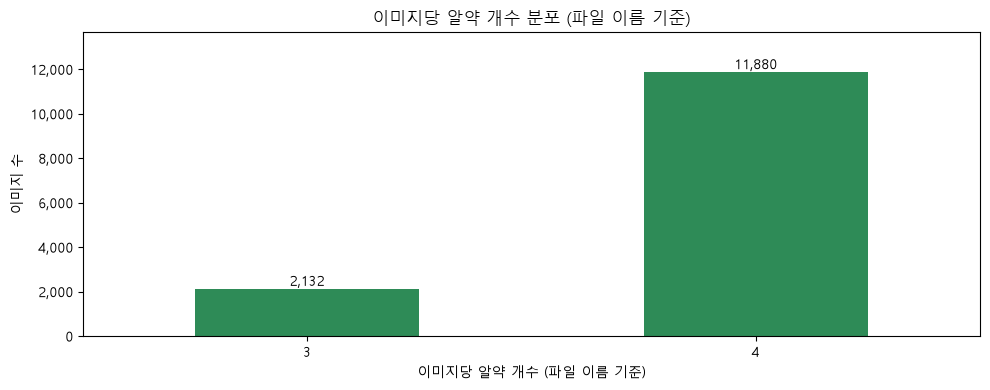

In [15]:
pill_counts = img_df["n_codes_in_name"].value_counts().sort_index().rename("이미지 수").to_frame()
pill_counts.index.name = "이미지당 알약 개수 (파일 이름 기준)"
pill_counts["비율(%)"] = pill_counts["이미지 수"] / len(img_df) * 100
print(f"전체 이미지: {len(img_df):,}장")
display(pill_counts.style.format({"이미지 수": "{:,.0f}", "비율(%)": "{:.1f}%"}))

ax = pill_counts["이미지 수"].plot.bar(figsize=(10, 4), rot=0, color="seagreen")
ax.set(
    xlabel="이미지당 알약 개수 (파일 이름 기준)",
    ylabel="이미지 수",
    title="이미지당 알약 개수 분포 (파일 이름 기준)",
)
ax.bar_label(ax.containers[0], labels=[f"{count:,}" for count in pill_counts["이미지 수"]])
ax.set_ylim(0, pill_counts["이미지 수"].max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
plt.tight_layout()
plt.show()

## 4. 대회 데이터와 비교

대회 데이터(`data/raw`)가 있을 때만 실행합니다. 대회 이미지가 AI Hub 조합 데이터에서 나왔을 수 있으므로,
같은 파일 이름이 대회 **test**에 있으면 그대로 학습에 넣으면 안 됩니다(누수). 이름만 비교하므로
같은 사진인지는 해시나 눈으로 다시 확인합니다.

In [16]:
raw_dir = ROOT / "data" / "raw"
if (raw_dir / "sprint_ai_project1_data").is_dir():
    raw_dir = raw_dir / "sprint_ai_project1_data"

if (raw_dir / "train_annotations").is_dir():
    comp_ann_df, _ = load_annotations(raw_dir / "train_annotations")
    comp_files = {
        split: {p.name for p in list_images(raw_dir / f"{split}_images")}
        for split in ["train", "test"]
    }
    aihub_files = set(img_df["file_name"])
    for split, files in comp_files.items():
        n_same = len(files & aihub_files)
        print(f"대회 {split} 이미지 {len(files)}장 중 AI Hub에 같은 이름: {n_same}장")

    comp_cats = set(comp_ann_df["category_id"])
    aihub_cats = set(cat_df["category_id"])
    print(
        f"클래스: 대회 {len(comp_cats)}종, AI Hub {len(aihub_cats)}종, "
        f"겹침 {len(comp_cats & aihub_cats)}종, 대회에만 있음 {len(comp_cats - aihub_cats)}종"
    )
    aihub_only_cat_df = (
        cat_df[~cat_df["category_id"].isin(comp_cats)]
        .sort_values("category_id")
        .reset_index(drop=True)
    )
    print(f"AI Hub에만 있는 알약: {len(aihub_only_cat_df)}종 (대회 train 라벨 기준)")
    print("현재 불러온 AI Hub 데이터 범위의 결과이며, 대회 test의 종류는 확인하지 않았습니다.")
    with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
        display(aihub_only_cat_df)
    overlap_cat_df = cat_df[cat_df["category_id"].isin(comp_cats)]
    print("대회 클래스의 AI Hub bbox 수")
    display(overlap_cat_df["n_boxes"].describe().to_frame().T)
else:
    print(f"대회 데이터가 없어 건너뜁니다: {raw_dir}")

대회 train 이미지 232장 중 AI Hub에 같은 이름: 0장
대회 test 이미지 842장 중 AI Hub에 같은 이름: 0장
클래스: 대회 56종, AI Hub 116종, 겹침 54종, 대회에만 있음 2종
AI Hub에만 있는 알약: 62종 (대회 train 라벨 기준)
현재 불러온 AI Hub 데이터 범위의 결과이며, 대회 test의 종류는 확인하지 않았습니다.


,category_id,category_name,drug_N,dl_name,dl_name_en,n_boxes,n_images
0,250,마그밀정(수산화마그네슘),K-000250,마그밀정(수산화마그네슘),Magmil Tab. 500mg,540,540
1,573,게보린정 300mg/PTP,K-000573,게보린정 300mg/PTP,Geworin Tab.,450,450
2,1866,알마겔정(알마게이트)(수출명:유한가스트라겔정),K-001866,알마겔정(알마게이트)(수출명:유한가스트라겔정),Almagel Tab.,537,537
3,3614,동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물),K-003614,동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물),Opalmon Tab. Dong-A,642,642
4,4378,타이레놀정500mg,K-004378,타이레놀정500mg,Tylenol Tab. 500mg,405,405
5,5000,비유피-4정 20mg,K-005000,비유피-4정 20mg,BUP-4 Tab. 20mg,297,297
6,5002,엘도스캡슐(에르도스테인)(수출용),K-005002,엘도스캡슐(에르도스테인)(수출용),Erdos Cap.,450,450
7,5094,삼남건조수산화알루미늄겔정,K-005094,삼남건조수산화알루미늄겔정,Dried Aluminium Hydroxide Gel Tab. Samnam,294,294
8,5391,프로스카정,K-005391,프로스카정,Proscar Tab. 5mg,297,297
9,5886,타이레놀이알서방정(아세트아미노펜)(수출용),K-005886,타이레놀이알서방정(아세트아미노펜)(수출용),Tylenol 8 hours ER Tab.,345,345


대회 클래스의 AI Hub bbox 수


,count,mean,std,min,25%,50%,75%,max
n_boxes,54.0,337.333333,195.851118,129.0,165.0,327.0,440.25,924.0


## 5. 예시 이미지

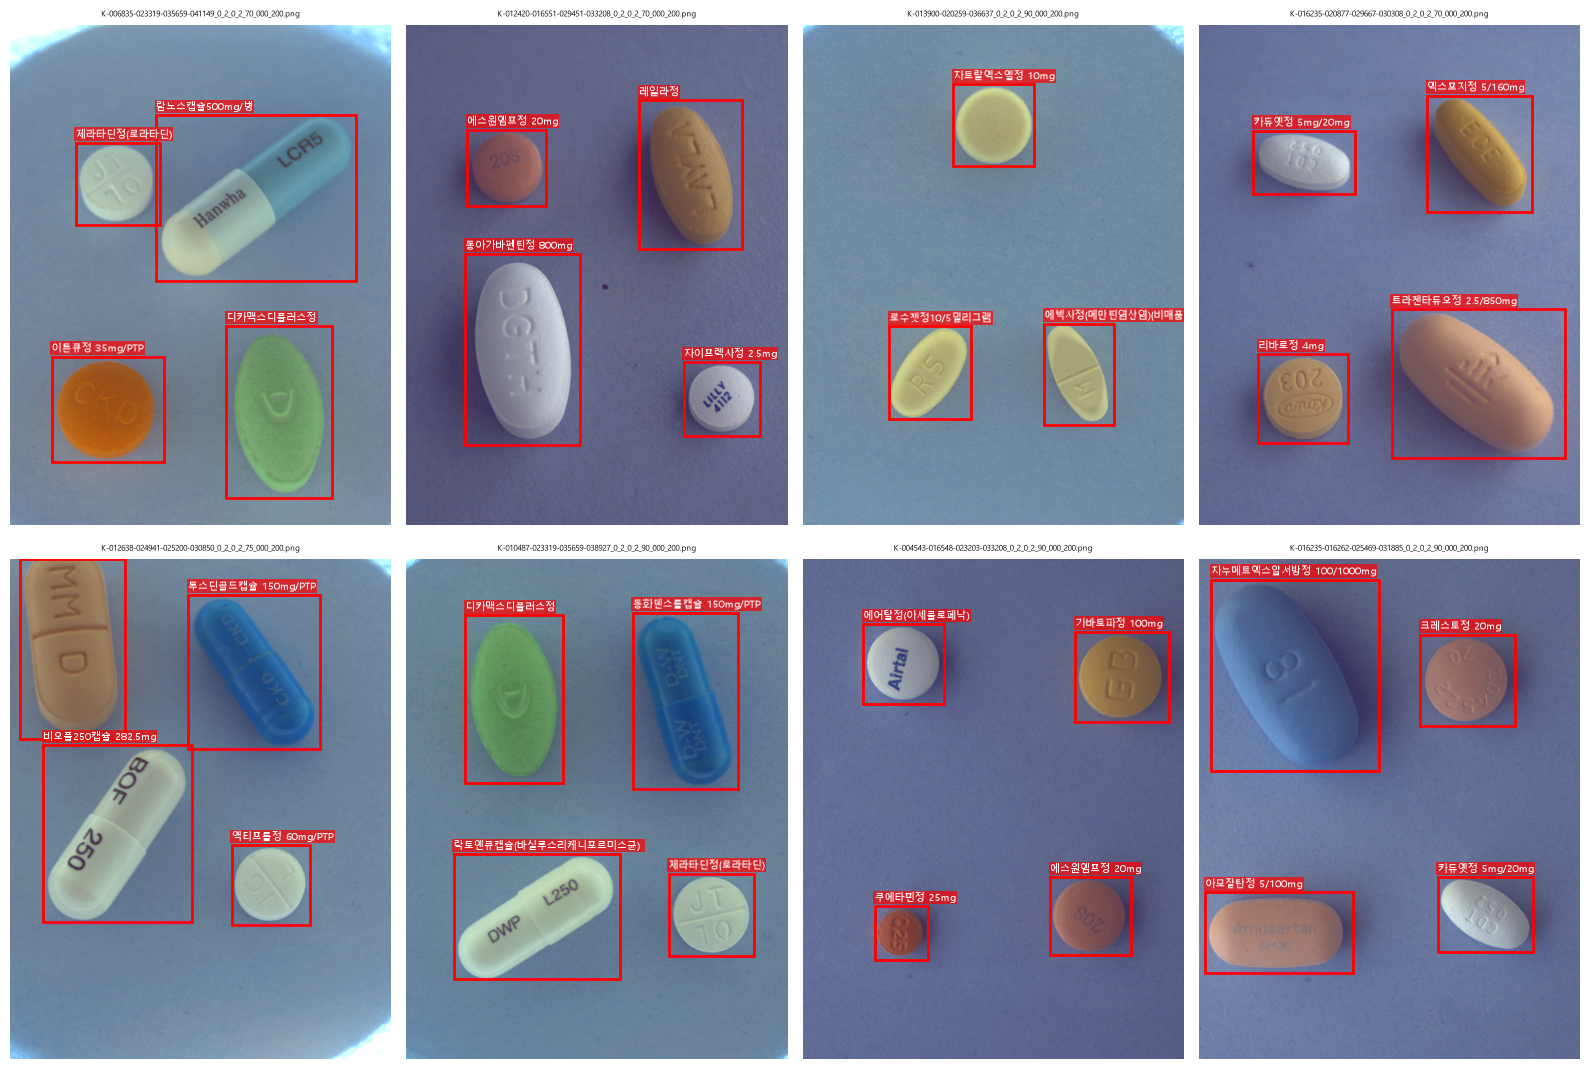

In [17]:
sample = img_df[img_df["n_boxes"] > 0].sample(
    min(8, (img_df["n_boxes"] > 0).sum()), random_state=SEED
)
fig, axes = image_grid(len(sample), cols=4)
for ax, file_name in zip(axes, sample["file_name"], strict=True):
    show_image(ax, img_path[file_name], title=file_name, fontsize=6)
    draw_bboxes(ax, ann_df[ann_df["file_name"] == file_name], label_col="dl_name")
fig.tight_layout()
plt.show()

## bbox 0개, 2개, 5개, 6개 별 이미지 2개씩 확인

bbox 0개: 전체 3,515장


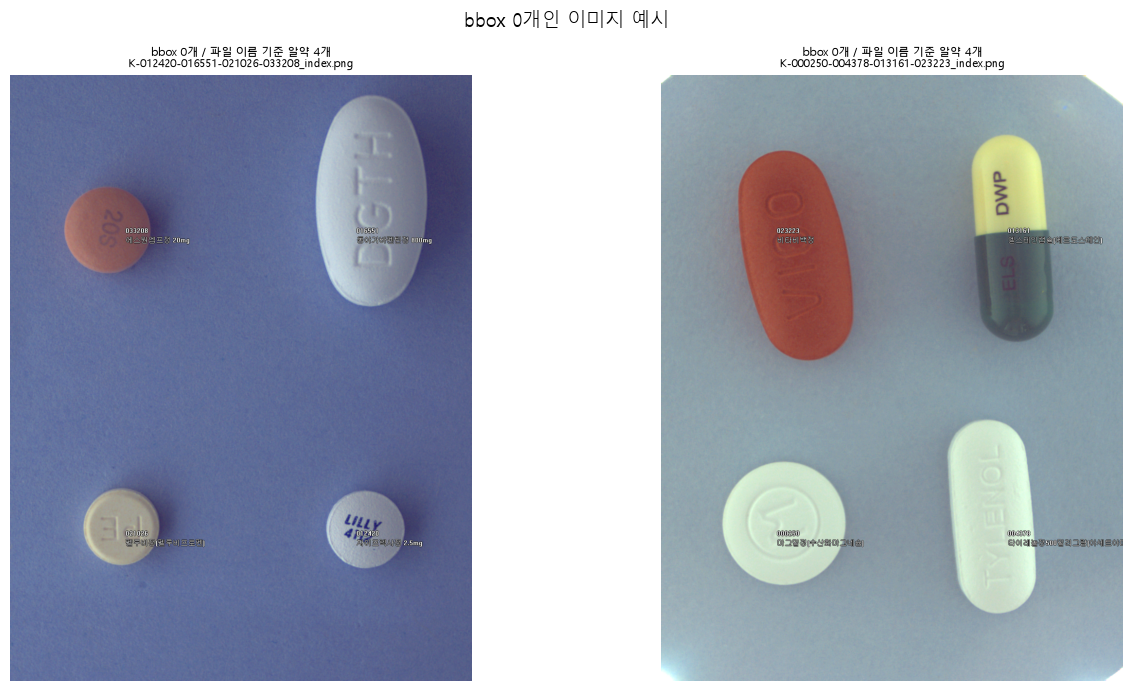

bbox 2개: 전체 1장


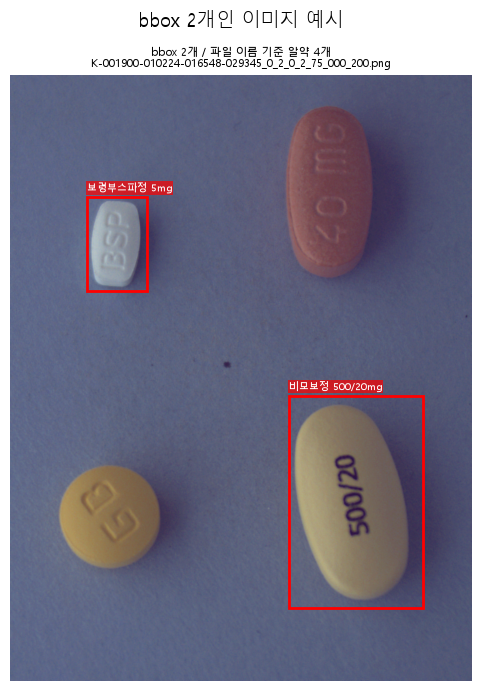

bbox 5개: 전체 12장


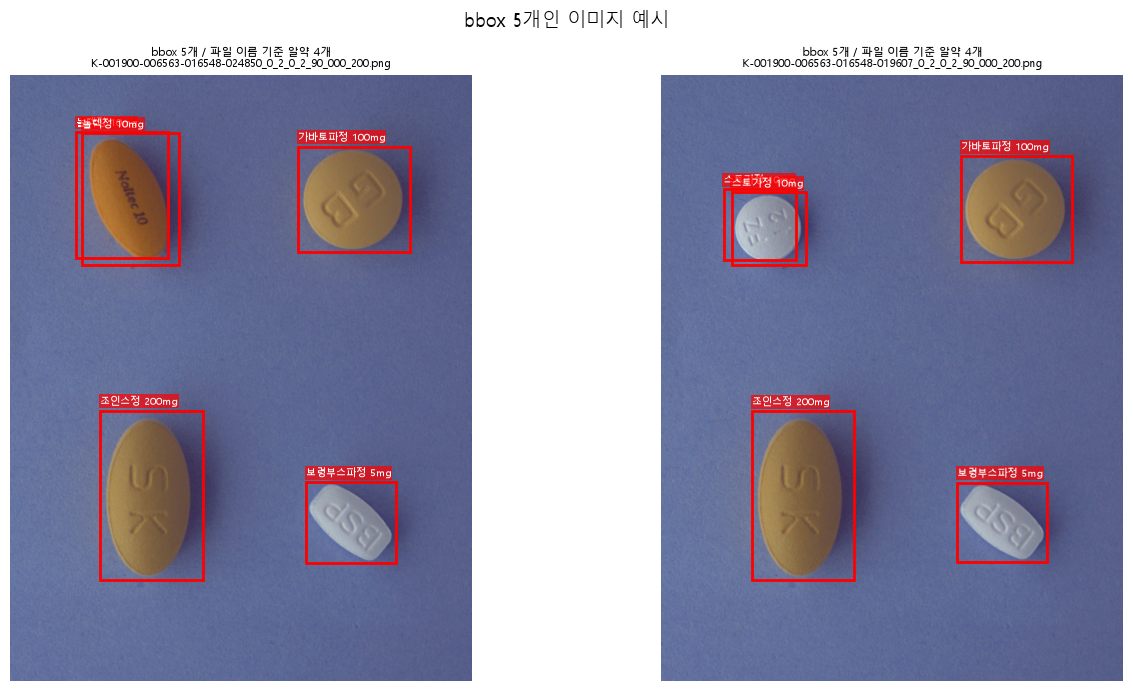

bbox 6개: 전체 5장


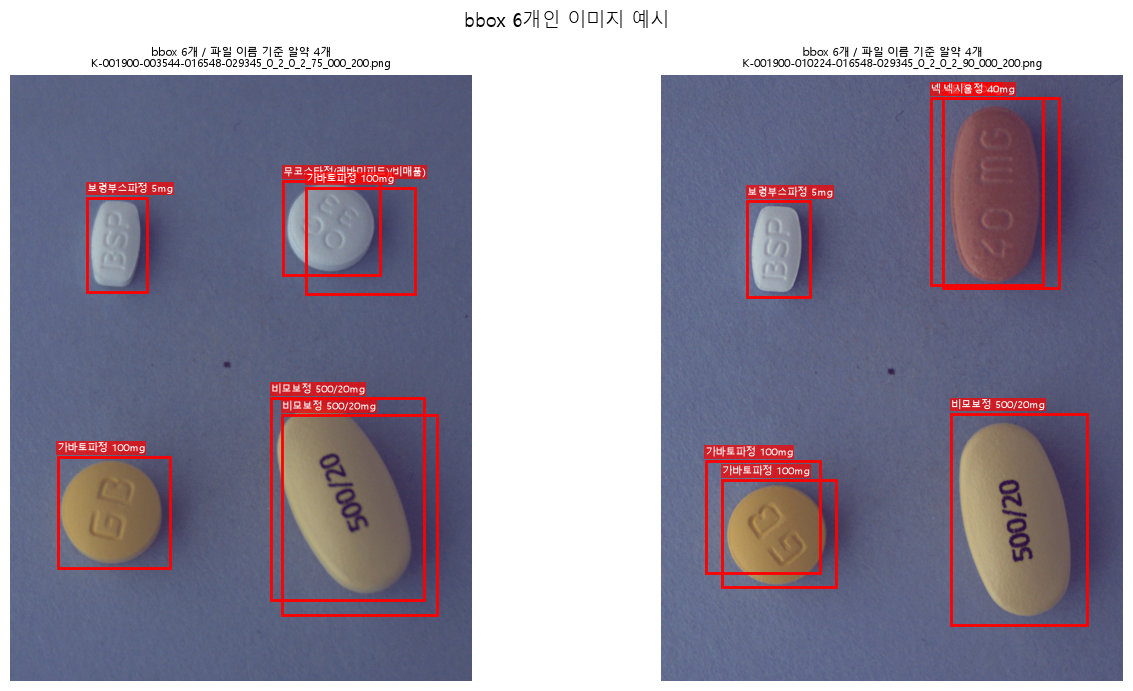

In [18]:
# bbox 수가 0·2·5·6개인 이미지를 각각 최대 2장씩 확인한다.
# 파일 이름의 약 코드 수와 비교하며, 누락·중복 여부는 이미지를 보고 판단한다.
for bbox_count in [0, 2, 5, 6]:
    candidates = img_df[img_df["n_boxes"] == bbox_count]
    print(f"bbox {bbox_count}개: 전체 {len(candidates):,}장")
    if candidates.empty:
        print("해당 이미지가 없습니다.")
        continue

    examples = candidates.sample(n=min(2, len(candidates)), random_state=SEED)
    fig, axes = image_grid(len(examples), cols=2, cell=(7, 7))
    for ax, row in zip(axes, examples.itertuples(), strict=True):
        title = (
            f"bbox {row.n_boxes}개 / 파일 이름 기준 알약 {row.n_codes_in_name}개\n{row.file_name}"
        )
        show_image(ax, img_path[row.file_name], title=title, fontsize=8)
        draw_bboxes(ax, ann_df[ann_df["file_name"] == row.file_name], label_col="dl_name")
    fig.suptitle(f"bbox {bbox_count}개인 이미지 예시", fontsize=14)
    fig.tight_layout()
    plt.show()

,bbox 개수,파일 이름 기준 알약 개수,이미지 수
0,3,4,26
1,4,3,0


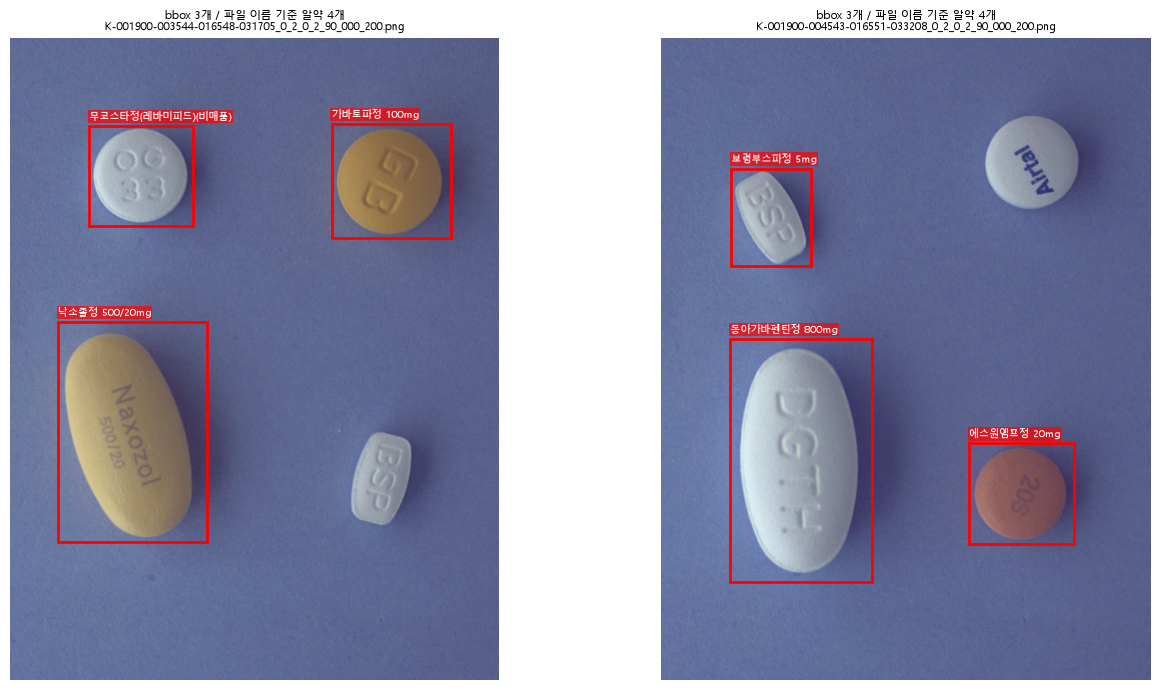

bbox 4개 / 알약 3개: 해당 이미지가 없습니다.
bbox 개수별 총 결측치 분포 (파일 이름 기준 누락 의심)


,전체 이미지,누락 의심 이미지,누락 의심 bbox,초과 의심 이미지,누락 의심 비율(%)
bbox 개수,,,,,
0,"3,515","3,515","13,521",0,100.0%
2,1,1,2,0,100.0%
3,"1,619",26,26,0,1.6%
4,"8,860",0,0,0,0.0%
5,12,0,0,12,0.0%
6,5,0,0,5,0.0%
전체,"14,012","3,542","13,549",17,25.3%


In [19]:
# 요청한 두 경우만 간단한 건수 표와 예시 이미지로 확인한다.
# 알약 수는 파일 이름 기준이며, 실제 누락·중복은 이미지를 보고 판단한다.
requested_cases = [(3, 4), (4, 3)]
case_summary = pd.DataFrame(
    [
        {
            "bbox 개수": bbox_count,
            "파일 이름 기준 알약 개수": pill_count,
            "이미지 수": int(
                (img_df["n_boxes"].eq(bbox_count) & img_df["n_codes_in_name"].eq(pill_count)).sum()
            ),
        }
        for bbox_count, pill_count in requested_cases
    ]
)
display(case_summary)

for bbox_count, pill_count in requested_cases:
    candidates = img_df[img_df["n_boxes"].eq(bbox_count) & img_df["n_codes_in_name"].eq(pill_count)]
    if candidates.empty:
        print(f"bbox {bbox_count}개 / 알약 {pill_count}개: 해당 이미지가 없습니다.")
        continue

    examples = candidates.sample(n=min(2, len(candidates)), random_state=SEED)
    fig, axes = image_grid(len(examples), cols=2, cell=(7, 7))
    for ax, row in zip(axes, examples.itertuples(), strict=True):
        title = (
            f"bbox {row.n_boxes}개 / 파일 이름 기준 알약 {row.n_codes_in_name}개\n{row.file_name}"
        )
        show_image(ax, img_path[row.file_name], title=title, fontsize=8)
        draw_bboxes(ax, ann_df[ann_df["file_name"] == row.file_name], label_col="dl_name")
    fig.tight_layout()
    plt.show()

# 전체 이미지에서 bbox 개수별 누락 의심 분포를 집계한다.
# bbox가 더 많은 경우는 누락에 합치지 않고 초과 의심으로 구분한다.
print("bbox 개수별 총 결측치 분포 (파일 이름 기준 누락 의심)")
missing_distribution = (
    img_df.assign(
        missing_image=img_df["n_boxes"].lt(img_df["n_codes_in_name"]),
        missing_boxes=(img_df["n_codes_in_name"] - img_df["n_boxes"]).clip(lower=0),
        excess_image=img_df["n_boxes"].gt(img_df["n_codes_in_name"]),
    )
    .groupby("n_boxes")
    .agg(
        전체_이미지=("file_name", "size"),
        누락_의심_이미지=("missing_image", "sum"),
        누락_의심_bbox=("missing_boxes", "sum"),
        초과_의심_이미지=("excess_image", "sum"),
    )
    .rename_axis("bbox 개수")
)
missing_distribution["누락 의심 비율(%)"] = (
    missing_distribution["누락_의심_이미지"] / missing_distribution["전체_이미지"] * 100
)
missing_distribution.loc["전체"] = missing_distribution.sum()
missing_distribution.loc["전체", "누락 의심 비율(%)"] = (
    missing_distribution.loc["전체", "누락_의심_이미지"]
    / missing_distribution.loc["전체", "전체_이미지"]
    * 100
)
missing_distribution = missing_distribution.rename(columns=lambda name: name.replace("_", " "))
display(
    missing_distribution.style.format(
        {
            column: "{:,.0f}"
            for column in missing_distribution.columns
            if column != "누락 의심 비율(%)"
        }
        | {"누락 의심 비율(%)": "{:.1f}%"}
    )
)

In [ ]:
# OpenCV 후보 분석만 수행한다. 원본 라벨·이미지·보정 기록은 저장하거나 변경하지 않는다.
import cv2
from PIL import Image
from tqdm.auto import tqdm

from visualization import draw_bbox

CV_MAX_SIDE = 900
CV_MIN_AREA_RATIO = 0.0005
CV_MAX_AREA_RATIO = 0.25
CV_MIN_COVERAGE = 0.98
CV_MATCH_COVERAGE = 0.10
CV_MARGIN = 4  # 원본 이미지 좌표 기준 후보 bbox 여유


def segment_combo_pills(image_path: Path) -> tuple[np.ndarray, list[np.ndarray], float]:
    """테두리 배경색과 GrabCut으로 알약 영역 후보를 추정한다."""
    with Image.open(image_path) as image:
        rgb = np.asarray(image.convert("RGB"))
    height, width = rgb.shape[:2]
    scale = min(1.0, CV_MAX_SIDE / max(height, width))
    small = cv2.resize(rgb, (round(width * scale), round(height * scale)))
    lab = cv2.cvtColor(small, cv2.COLOR_RGB2LAB).astype(np.float32)
    border = np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]])
    background = np.median(border, axis=0)
    distance = np.linalg.norm(lab - background, axis=2)
    distance = np.clip(distance, 0, 255).astype(np.uint8)
    _, foreground = cv2.threshold(distance, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    foreground = cv2.morphologyEx(foreground, cv2.MORPH_CLOSE, kernel)
    definite_fg = cv2.erode(foreground, kernel)
    possible_fg = cv2.dilate(foreground, kernel, iterations=3)
    mask = np.full(foreground.shape, cv2.GC_BGD, dtype=np.uint8)
    mask[possible_fg > 0] = cv2.GC_PR_FGD
    mask[definite_fg > 0] = cv2.GC_FGD
    if np.any(mask == cv2.GC_FGD) and np.any(mask == cv2.GC_BGD):
        cv2.grabCut(
            small, mask, None, np.zeros((1, 65)), np.zeros((1, 65)), 3, cv2.GC_INIT_WITH_MASK
        )
        foreground = np.isin(mask, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype(np.uint8)
    else:
        foreground = (foreground > 0).astype(np.uint8)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(foreground)
    components = [
        labels == index
        for index in range(1, count)
        if CV_MIN_AREA_RATIO <= stats[index, cv2.CC_STAT_AREA] / labels.size <= CV_MAX_AREA_RATIO
    ]
    return rgb, components, scale


def inspect_combo_cv(file_name: str, expected_count: int) -> tuple[list[dict], dict]:
    """추정 몸체의 기존 bbox 포함률과 누락 후보를 계산한다."""
    rgb, components, _ = segment_combo_pills(img_path[file_name])
    height, width = rgb.shape[:2]
    boxes = ann_df.loc[ann_df["file_name"].eq(file_name), ["x", "y", "w", "h"]]
    box_array = boxes.to_numpy(dtype=float)
    rows = []
    boundary = False
    coverages = []
    for component in components:
        ys, xs = np.where(component)
        boundary |= bool(
            xs.min() == 0
            or ys.min() == 0
            or xs.max() == component.shape[1] - 1
            or ys.max() == component.shape[0] - 1
        )
        # 가로·세로의 실제 축소율로 원본 이미지의 픽셀 중심 좌표를 복원한다.
        px = (xs + 0.5) * width / component.shape[1]
        py = (ys + 0.5) * height / component.shape[0]
        coverage = np.array(
            [
                np.mean((px >= x) & (px < x + w) & (py >= y) & (py < y + h))
                if np.isfinite([x, y, w, h]).all() and w > 0 and h > 0
                else 0.0
                for x, y, w, h in box_array
            ]
        )
        coverages.append(coverage)
        left = max(0, xs.min() * width / component.shape[1] - CV_MARGIN)
        top = max(0, ys.min() * height / component.shape[0] - CV_MARGIN)
        right = min(width, (xs.max() + 1) * width / component.shape[1] + CV_MARGIN)
        bottom = min(height, (ys.max() + 1) * height / component.shape[0] + CV_MARGIN)
        best = float(coverage.max()) if coverage.size else 0.0
        rows.append(
            {
                "file_name": file_name,
                "coverage": best,
                "box_index": int(coverage.argmax()) if coverage.size else -1,
                "candidate_bbox": [left, top, right - left, bottom - top],
                "status": "누락 후보"
                if best < CV_MATCH_COVERAGE
                else ("잘림·덜 감쌈 의심" if best < CV_MIN_COVERAGE else "포함률 기준 충족"),
            }
        )
    matched = [r["box_index"] for r in rows if r["coverage"] >= CV_MATCH_COVERAGE]
    ambiguous = len(matched) != len(set(matched)) or any(
        (coverage >= CV_MATCH_COVERAGE).sum() > 1 for coverage in coverages
    )
    reliable = len(components) == expected_count and not boundary and not ambiguous
    for row in rows:
        row["review_required"] = not reliable
    return rows, {
        "file_name": file_name,
        "추정 영역 수": len(components),
        "파일 이름 알약 수": expected_count,
        "판정 보류": not reliable,
        "영역 수 불일치": len(components) != expected_count,
        "이미지 경계 접촉": boundary,
        "대응 모호": ambiguous,
    }


cv2.setRNGSeed(SEED)
cv_rows, cv_image_rows, cv_errors = [], [], []
for image_row in tqdm(img_df.itertuples(), total=len(img_df), desc="OpenCV 알약 영역 검사"):
    try:
        component_rows, image_result = inspect_combo_cv(
            image_row.file_name, image_row.n_codes_in_name
        )
        cv_rows.extend(component_rows)
        cv_image_rows.append(image_result)
    except (OSError, ValueError, cv2.error) as error:
        cv_errors.append({"file_name": image_row.file_name, "error": str(error)})

cv_candidates = pd.DataFrame(
    cv_rows,
    columns=["file_name", "coverage", "box_index", "candidate_bbox", "status", "review_required"],
)
cv_image_results = pd.DataFrame(
    cv_image_rows,
    columns=[
        "file_name",
        "추정 영역 수",
        "파일 이름 알약 수",
        "판정 보류",
        "영역 수 불일치",
        "이미지 경계 접촉",
        "대응 모호",
    ],
)
cv_error_results = pd.DataFrame(cv_errors, columns=["file_name", "error"])
print("OpenCV 추정 결과입니다. 기준 충족은 실제 bbox 정확성을 보장하지 않습니다.")
print("누락 후보 bbox는 클래스 미지정·미검수이며 원본 라벨에 반영하지 않습니다.")
display(
    pd.DataFrame(
        [
            {"구분": "검사 완료 이미지", "이미지 수": len(cv_image_results)},
            {
                "구분": "영역 수·경계·대응 문제로 판정 보류",
                "이미지 수": int(cv_image_results["판정 보류"].sum()),
            },
            {"구분": "읽기·처리 오류", "이미지 수": len(cv_error_results)},
        ]
    )
)
if not cv_candidates.empty:
    display(
        cv_candidates.groupby(["status", "review_required"])
        .agg(영역_수=("file_name", "size"), 이미지_수=("file_name", "nunique"))
        .rename_axis(index=["추정 결과", "판정 보류"])
    )
else:
    print("추정 영역이 없습니다. 정상 0건이 아니라 분리 결과를 확인해야 합니다.")

/home/username/projects/pill-bbox/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
OpenCV 알약 영역 검사:  67%|██████▋   | 9343/14012 [10:53:17<41:59,  1.85it/s]       

In [ ]:
# 빨강: 기존 bbox, 초록: 누락 추가 후보, 주황: 잘림·덜 감쌈 수정 후보.
# 종류별 최대 2장, 같은 이미지의 기존 라벨과 후보를 나란히 비교한다.
for issue in ["누락 후보", "잘림·덜 감쌈 의심"]:
    issue_rows = cv_candidates[cv_candidates["status"].eq(issue)]
    print(f"{issue}: {issue_rows['file_name'].nunique():,}장 / {len(issue_rows):,}영역")
    files = issue_rows["file_name"].drop_duplicates()
    if files.empty:
        print("해당 후보가 검출되지 않았습니다. 실제 문제가 없다는 뜻은 아닙니다.")
        continue
    example_files = files.sample(n=min(2, len(files)), random_state=SEED)
    fig, axes = image_grid(len(example_files) * 2, cols=2, cell=(7, 7))
    for index, file_name in enumerate(example_files):
        original = ann_df[ann_df["file_name"].eq(file_name)]
        proposals = cv_candidates[cv_candidates["file_name"].eq(file_name)]
        review_required = bool(proposals["review_required"].any())
        for offset, label in [(0, "기존 bbox"), (1, "OpenCV 후보 (미검수)")]:
            ax = axes[index * 2 + offset]
            show_image(
                ax,
                img_path[file_name],
                title=f"{label} / {'판정 보류' if review_required else '자동 추정'}\n{file_name}",
                fontsize=8,
            )
            draw_bboxes(ax, original, label_col=None, color="red")
            if offset == 1:
                for proposal in proposals.itertuples():
                    if proposal.status == "포함률 기준 충족":
                        continue
                    color = "lime" if proposal.status == "누락 후보" else "orange"
                    draw_bbox(
                        ax,
                        proposal.candidate_bbox,
                        label=f"{proposal.status}: 기존 포함률 {proposal.coverage:.1%}",
                        color=color,
                        linestyle="--",
                    )
        display(
            proposals[["status", "coverage", "candidate_bbox", "review_required"]].rename(
                columns={
                    "status": "추정 결과",
                    "coverage": "기존 bbox 몸체 포함률",
                    "candidate_bbox": "후보 bbox [x,y,w,h]",
                    "review_required": "판정 보류",
                }
            )
        )
    fig.tight_layout()
    plt.show()